<div dir="rtl">

# 🤖 DemoCheck - מחברת EDA (M2)

> 💡 **התובנה:** גילינו שמפעילים חלשים לא מזיזים את היד רחוק יותר, אלא לאט יותר ועם יותר עצירות: ההקלטות שלהם ארוכות פי 2 (חציון 7.3 שניות מול 3.5 אצל הטובים), בזמן שהמסלול ארוך רק בכ-25%. למשתמש זה אומר שמשך ההקלטה ומהירות היד הם הסימן הראשון לבדוק.

> 🎯 **ה-baseline:** לנחש תמיד "הקלטה תקינה" נותן Accuracy של **66.7%**. זה המספר שהמודל ב-M3 צריך לנצח.

**הבעיה:** הקלטות טלאופרציה גרועות נכנסות לאימון של רובוטים ופוגעות בו.
**ה-y:** `is_worse` - האם ההקלטה נעשתה על ידי מפעיל מהקבוצה החלשה (1) או לא (0).
**הנתונים:** robomimic Lift MH (Stanford): 300 הקלטות של 6 מפעילים אנושיים שהפעילו זרוע Panda (בסימולציה) והרימו קובייה. 50 הקלטות לכל מפעיל. החוקרים דירגו כל מפעיל: worse / okay / better.
**שורה = הקלטה אחת.** את הטבלה יוצר `scripts/make_features.py`, שמחשב לכל הקלטה מספרים שמתארים איך המפעיל הזיז את היד.

</div>

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
DATA = Path("..") / "data"
df = pd.read_csv(DATA / "demos_features.csv")
print(df.shape)
df.head()

(300, 14)


,demo,operator,quality,n_steps,duration_s,path_length_m,straightness,mean_speed,max_speed,mean_joint_speed,action_jerk,gripper_switches,idle_fraction,is_worse
0,demo_0,better_1,better,48,2.40,0.317673,0.516494,0.135180,0.257945,0.620210,0.123901,1,0.042553,0
1,demo_1,better_1,better,55,2.75,0.311015,0.524302,0.115191,0.251608,0.513892,0.139888,1,0.111111,0
2,demo_2,better_1,better,46,2.30,0.310920,0.625660,0.138187,0.284664,0.563345,0.123669,1,0.022222,0
3,demo_3,better_1,better,45,2.25,0.309195,0.613757,0.140543,0.291917,0.580959,0.125472,1,0.000000,0
4,demo_4,better_1,better,43,2.15,0.296163,0.544367,0.141030,0.255476,0.645888,0.121251,1,0.047619,0


<div dir="rtl">

## 1️⃣ סוגי העמודות

</div>

In [2]:
types = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "ערכים שונים": df.nunique(),
    "סוג": ["מזהה", "מזהה (מפעיל)", "קטגורית (מקור ה-y)"]
           + ["מספרית (ספירה)" if c in ("n_steps", "gripper_switches") else "מספרית"
              for c in df.columns[3:-1]]
           + ["בינארית (y)"],
})
types

,dtype,ערכים שונים,סוג
demo,str,300,מזהה
operator,str,6,מזהה (מפעיל)
quality,str,3,קטגורית (מקור ה-y)
n_steps,int64,125,מספרית (ספירה)
duration_s,float64,125,מספרית
path_length_m,float64,300,מספרית
straightness,float64,300,מספרית
mean_speed,float64,300,מספרית
max_speed,float64,300,מספרית
mean_joint_speed,float64,300,מספרית


<div dir="rtl">

| עמודה | מה היא אומרת |
|---|---|
| `duration_s` | כמה שניות נמשכה ההקלטה |
| `path_length_m` | כמה מטרים היד עברה בסך הכל |
| `straightness` | כמה ישר המסלול (1 = קו ישר, קרוב ל-0 = הרבה סיבובים) |
| `mean_speed`, `max_speed` | מהירות היד הממוצעת והמקסימלית (מטר לשנייה) |
| `mean_joint_speed` | מהירות ממוצעת של 7 המפרקים |
| `action_jerk` | כמה הפקודות של המפעיל קופצות מצעד לצעד (גבוה = תנועה עצבנית) |
| `gripper_switches` | כמה פעמים המפעיל פתח או סגר את הצבת |
| `idle_fraction` | איזה חלק מהזמן היד כמעט לא זזה (מתחת ל-2 ס"מ לשנייה) |

</div>

<div dir="rtl">

**מסקנה:** יש 14 עמודות: 2 מזהים (`demo`, `operator`), עמודה קטגורית אחת (`quality`), 10 עמודות מספריות שהן ה-X (אחת מהן, `n_steps`, כפולה ותימחק בניקוי), ועמודת y בינארית אחת. `operator` ו-`quality` **לא ייכנסו למודל**: הן קובעות את ה-y ישירות (ראו בדיקת הדליפה בסעיף 4).

</div>

<div dir="rtl">

## 2️⃣ איכות הנתונים וניקוי

</div>

In [3]:
print("ערכים חסרים:", int(df.isna().sum().sum()))
print("שורות כפולות:", int(df.duplicated(subset=df.columns[1:]).sum()))
print("n_steps מול duration_s, קורלציה:", round(df["n_steps"].corr(df["duration_s"]), 3))

ערכים חסרים: 0
שורות כפולות: 0
n_steps מול duration_s, קורלציה: 1.0


<div dir="rtl">

**מסקנה:** אין ערכים חסרים ואין כפילויות. `n_steps` ו-`duration_s` הן בדיוק אותו מידע (מספר צעדים חלקי 20 צעדים בשנייה), ולכן **מוחקים את `n_steps`**.

</div>

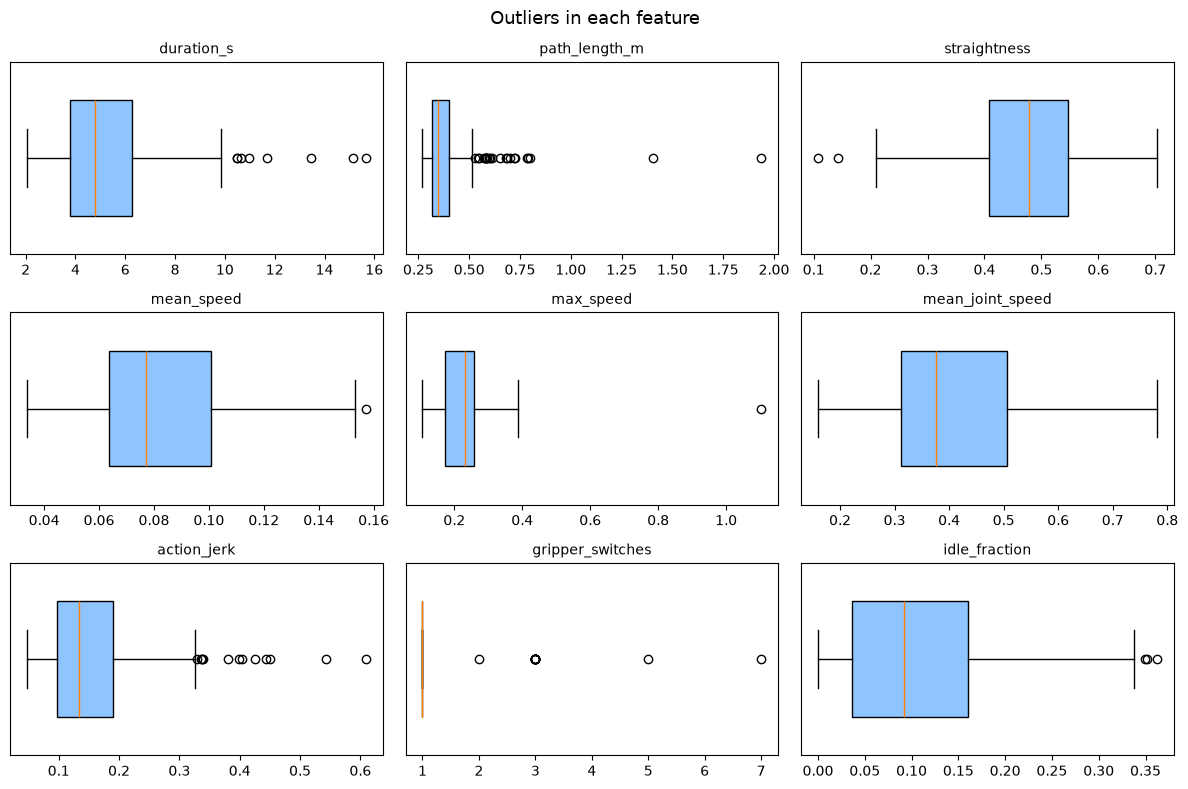

In [4]:
features = ["duration_s", "path_length_m", "straightness", "mean_speed", "max_speed",
            "mean_joint_speed", "action_jerk", "gripper_switches", "idle_fraction"]
fig, axes = plt.subplots(3, 3, figsize=(12, 8))
for ax, col in zip(axes.flat, features):
    ax.boxplot(df[col], orientation="horizontal", widths=0.6, patch_artist=True,
               boxprops=dict(facecolor="#8EC5FF"))
    ax.set_title(col, fontsize=10)
    ax.set_yticks([])
fig.suptitle("Outliers in each feature", fontsize=13)
plt.tight_layout()
plt.show()

In [5]:
df.nlargest(3, "duration_s")[["demo", "operator", "duration_s", "path_length_m", "max_speed", "gripper_switches"]]

,demo,operator,duration_s,path_length_m,max_speed,gripper_switches
259,demo_259,okay_1,15.65,1.936598,1.102909,1
241,demo_241,worse_1,15.15,1.402614,0.360938,7
79,demo_79,worse_2,13.45,0.497481,0.146711,3


<div dir="rtl">

**מסקנה:** יש חריגים בכל המאפיינים, למשל 2 הקלטות של כ-15 שניות (פי 3 מהחציון). בדקנו אותן: אלה הקלטות אמיתיות שבהן המפעיל התקשה (ב-demo_241 הצבת נפתחה ונסגרה 7 פעמים). **משאירים אותן**, כי בדיוק אותן המוצר צריך לתפוס. ב-`max_speed` יש קפיצה בודדת של 1.1 מטר לשנייה בפריים אחד (demo_259), ולכן המדד הזה פחות אמין מ-`mean_speed`.

</div>

In [6]:
clean = df.drop(columns=["n_steps"])
clean.to_csv(DATA / "demos_clean.csv", index=False)
print("שורות אחרי ניקוי:", len(clean), "| עמודות:", clean.shape[1])

שורות אחרי ניקוי: 300 | עמודות: 13


<div dir="rtl">

**סיכום הניקוי:** 300 שורות נשארו, נמחקה עמודה אחת כפולה (`n_steps`). הטבלה הנקייה נשמרה ב-`data/demos_clean.csv`.

</div>

<div dir="rtl">

## 3️⃣ התפלגויות

</div>

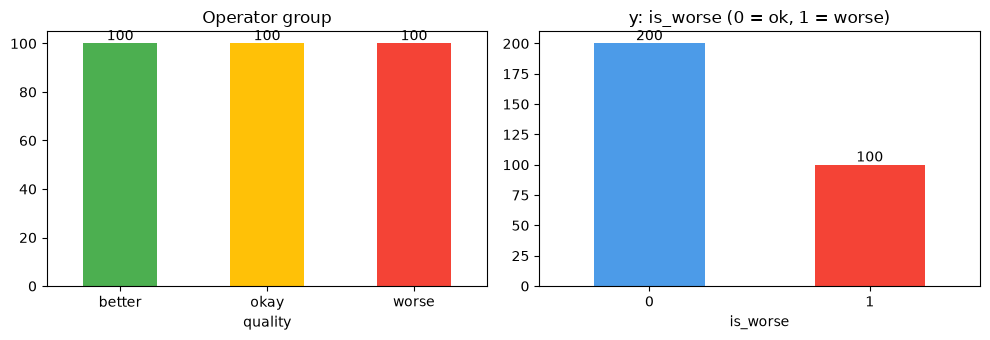

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
clean["quality"].value_counts().reindex(["better", "okay", "worse"]).plot.bar(
    ax=axes[0], color=["#4CAF50", "#FFC107", "#F44336"], rot=0, title="Operator group")
clean["is_worse"].value_counts().sort_index().plot.bar(
    ax=axes[1], color=["#4C9BE8", "#F44336"], rot=0, title="y: is_worse (0 = ok, 1 = worse)")
for ax in axes:
    ax.bar_label(ax.containers[0])
plt.tight_layout()
plt.show()

<div dir="rtl">

**מסקנה:** 100 הקלטות בכל קבוצת מפעילים. ב-y יש 100 "כן" (חלש) ו-200 "לא", כלומר יחס של 1 ל-2. זה לא מאוזן לגמרי, ולכן Accuracy לבד יטעה: מודל שתמיד עונה "לא" כבר מקבל 66.7%. ב-M3 נסתכל גם על Recall של המחלקה "חלש".

</div>

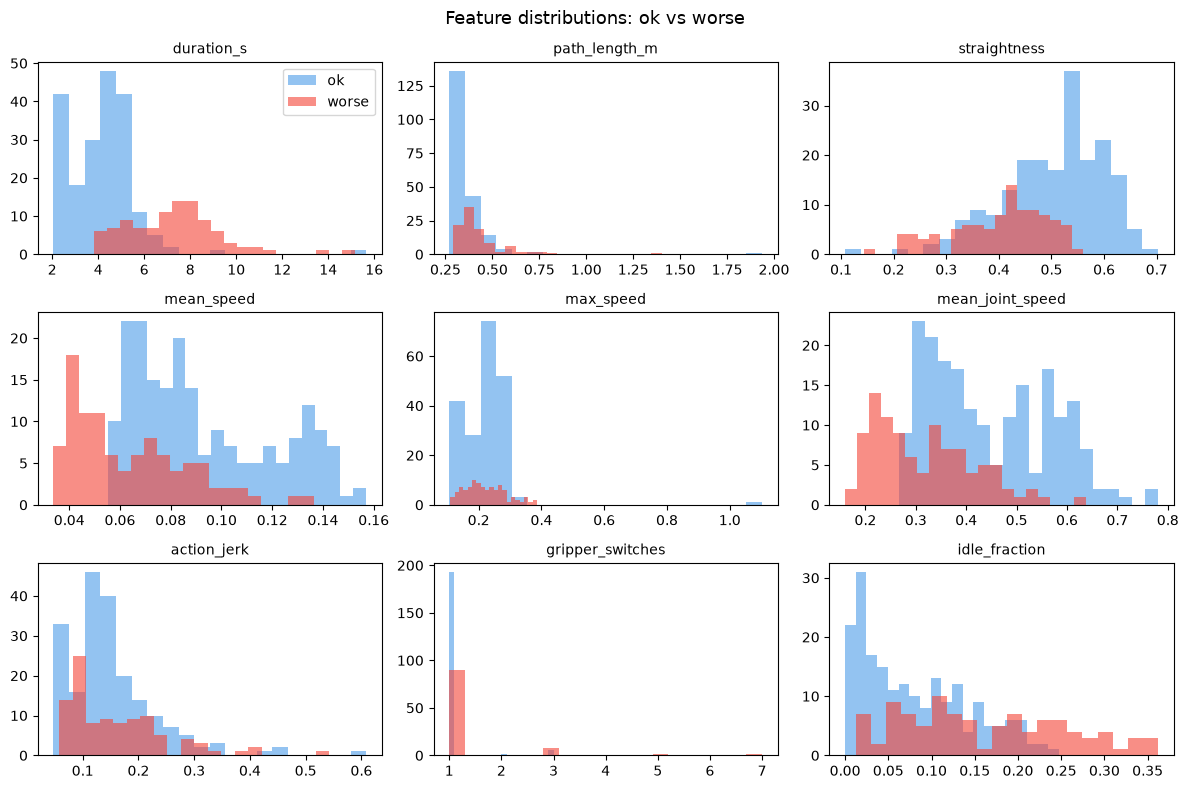

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(12, 8))
for ax, col in zip(axes.flat, features):
    ax.hist(clean.loc[clean.is_worse == 0, col], bins=20, alpha=0.6, color="#4C9BE8", label="ok")
    ax.hist(clean.loc[clean.is_worse == 1, col], bins=20, alpha=0.6, color="#F44336", label="worse")
    ax.set_title(col, fontsize=10)
axes[0, 0].legend()
fig.suptitle("Feature distributions: ok vs worse", fontsize=13)
plt.tight_layout()
plt.show()

In [9]:
clean.groupby("quality")[features].median().reindex(["better", "okay", "worse"]).round(3)

,duration_s,path_length_m,straightness,mean_speed,max_speed,mean_joint_speed,action_jerk,gripper_switches,idle_fraction
quality,,,,,,,,,
better,3.475,0.311,0.569,0.094,0.221,0.436,0.114,1.0,0.100
okay,4.500,0.370,0.444,0.085,0.243,0.421,0.175,1.0,0.058
worse,7.325,0.391,0.419,0.058,0.211,0.292,0.138,1.0,0.146


<div dir="rtl">

**מסקנה:** ההפרדה הכי ברורה היא ב-`duration_s`: ההקלטות של החלשים זזות ימינה (חציון 7.3 שניות מול 3.5 אצל הטובים). גם `mean_speed` נמוך יותר אצלם, ו-`idle_fraction` גבוה יותר. לעומת זאת, `max_speed` ו-`action_jerk` כמעט חופפים, כנראה שלא יעזרו. חשוב: גם ב-`duration_s` יש חפיפה בין 4 ל-6 שניות, ולכן מאפיין אחד לבד לא יספיק, והמודל יצטרך לשלב כמה.

</div>

In [10]:
pd.crosstab(clean["gripper_switches"] > 1, clean["quality"],
            rownames=["re-grasp (more than one switch)"])[["better", "okay", "worse"]]

quality,better,okay,worse
re-grasp (more than one switch),,,
False,100,93,90
True,0,7,10


<div dir="rtl">

**מסקנה:** אצל 283 מתוך 300 ההקלטות הצבת נסגרה פעם אחת בלבד. אחיזה חוזרת קרתה 10 פעמים אצל החלשים, 7 אצל הבינוניים, ו**אף פעם** אצל הטובים. זה מאפיין נדיר, אבל כשהוא מופיע הוא סימן חזק.

</div>

<div dir="rtl">

## 4️⃣ קורלציה ובדיקת דליפה

</div>

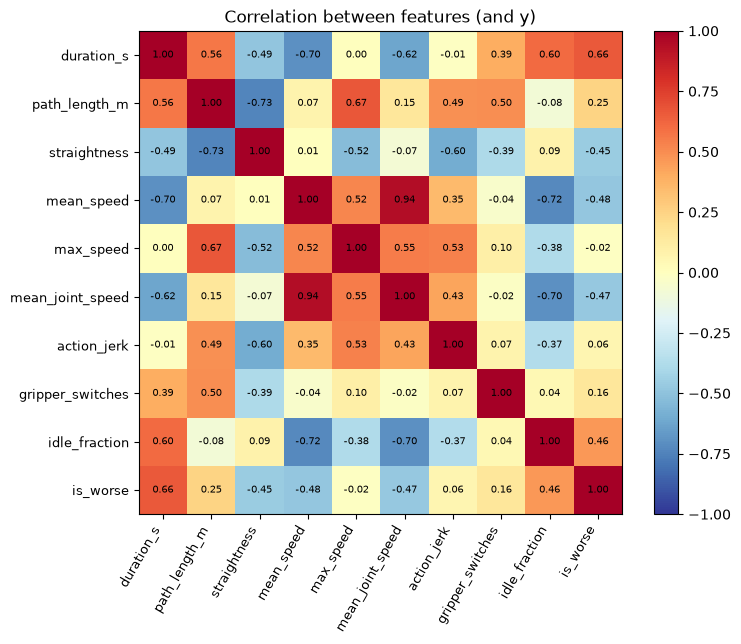

In [11]:
corr = clean[features + ["is_worse"]].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdYlBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right", fontsize=9)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=9)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im)
ax.set_title("Correlation between features (and y)")
plt.tight_layout()
plt.show()

<div dir="rtl">

**מסקנה:** `mean_speed` ו-`mean_joint_speed` כמעט זהות (0.94): שתיהן מודדות כמה מהר הזרוע זזה. ב-M3 כדאי לבחור רק אחת. `idle_fraction` הפוכה למהירות (0.72-), וזה הגיוני: כשהיד עומדת יותר, המהירות הממוצעת יורדת.

</div>

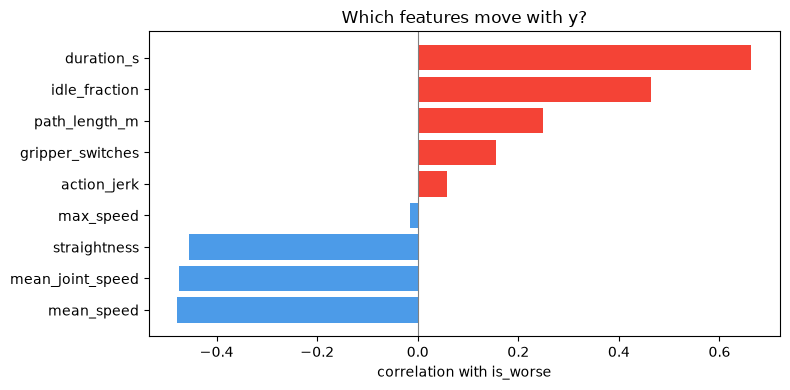

הקורלציה הכי גבוהה (בערך מוחלט): 0.66


In [12]:
corr_y = clean[features].corrwith(clean["is_worse"]).sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(corr_y.index, corr_y.values, color=["#F44336" if v > 0 else "#4C9BE8" for v in corr_y])
ax.axvline(0, color="gray", lw=0.8)
ax.set_xlabel("correlation with is_worse")
ax.set_title("Which features move with y?")
plt.tight_layout()
plt.show()
print("הקורלציה הכי גבוהה (בערך מוחלט):", round(corr_y.abs().max(), 2))

<div dir="rtl">

**מסקנה:** הקורלציה הכי חזקה מול ה-y היא של `duration_s` (0.66), ואחריה המהירות, הישירות וזמן העמידה (כ-0.46 עד 0.48 בערך מוחלט). אף מאפיין לא מגיע ל-0.9, כלומר **אין סימן לדליפה במאפיינים**. יש סיגנל: יש קשר ממשי בין איך שהיד זזה לבין הקבוצה של המפעיל.

</div>

In [13]:
print(pd.crosstab(clean["operator"], clean["is_worse"]))

is_worse   0   1
operator        
better_1  50   0
better_2  50   0
okay_1    50   0
okay_2    50   0
worse_1    0  50
worse_2    0  50


<div dir="rtl">

**מסקנה:** ⚠️ **דליפה שמצאנו:** העמודה `operator` קובעת את ה-y ב-100% (כל ההקלטות של worse_1 ו-worse_2 הן 1). לכן היא לא נכנסת למודל. ה-y נקבע לפי המפעיל, לא לפי כל הקלטה בנפרד, וזה כתוב ב-README.

</div>

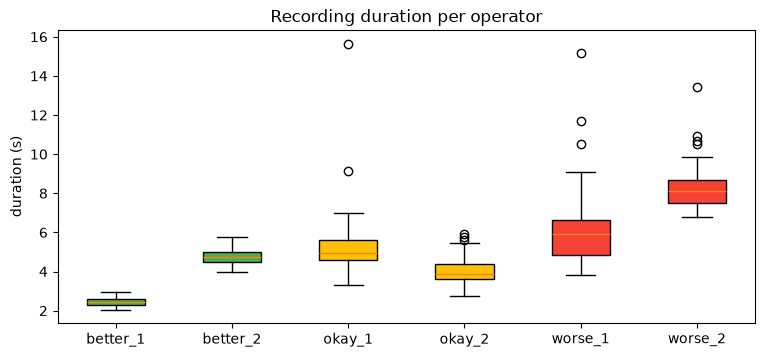

In [14]:
order = ["better_1", "better_2", "okay_1", "okay_2", "worse_1", "worse_2"]
colors = ["#4CAF50", "#4CAF50", "#FFC107", "#FFC107", "#F44336", "#F44336"]
fig, ax = plt.subplots(figsize=(9, 3.8))
bp = ax.boxplot([clean.loc[clean.operator == o, "duration_s"] for o in order],
                tick_labels=order, patch_artist=True)
for patch, c in zip(bp["boxes"], colors):
    patch.set_facecolor(c)
ax.set_ylabel("duration (s)")
ax.set_title("Recording duration per operator")
plt.show()

<div dir="rtl">

**מסקנה:** כל מפעיל הוא "סגנון" בפני עצמו: better_2 (חציון 4.8 שניות) איטי יותר מ-okay_2 (3.8). זה אומר שמודל יכול ללמוד **לזהות את המפעיל** במקום לזהות איכות. לכן ב-M3 נחלק train/test לפי מפעיל, ונבדוק אם המודל עובד גם על מפעיל שהוא לא ראה.

</div>

<div dir="rtl">

## 5️⃣ Baseline

</div>

In [15]:
majority = clean["is_worse"].mode()[0]
baseline_acc = (clean["is_worse"] == majority).mean()
print(f"הקטגוריה הנפוצה: {majority} (תקין) | Accuracy של baseline: {baseline_acc:.1%}")

הקטגוריה הנפוצה: 0 (תקין) | Accuracy של baseline: 66.7%


<div dir="rtl">

**מסקנה:** אם תמיד עונים "תקין", צודקים ב-66.7% מהמקרים, אבל לא תופסים אף הקלטה חלשה (Recall = 0). המודל ב-M3 צריך לעבור את 66.7%, ובעיקר לתפוס הקלטות חלשות.

</div>

<div dir="rtl">

## 📌 סיכום
- **יש סיגנל:** משך ההקלטה, מהירות היד, ישירות המסלול וזמן העמידה קשורים בבירור לקבוצת המפעיל.
- **הנתונים נקיים:** 300 שורות, אין חוסרים ואין כפילויות. נמחקה עמודה כפולה אחת, והחריגים נשארו כי הם חלק מהסיגנל.
- **סיכונים ל-M3:** (1) העמודה `operator` מדליפה את התשובה, ולכן לא נכנסת למודל. (2) המודל עלול ללמוד סגנון של מפעיל, ולכן נחלק לפי מפעיל. (3) הנתונים מסימולציה, וההקלטות של G1 מהמעבדה ישמשו בהמשך כבדיקה בעולם האמיתי.
- **Baseline:** Accuracy של 66.7%.

</div>